AIMS 5702 Artificial Intelligence in Practice (Fall 2026-27)

**AIMS 5702 Assignment 2 (in-class). Basic Training**

Please complete this notebook [8%]:

* Download it as **both** an `.ipynb` file and a `.pdf` file.
* Submit **both** files to Blackboard.
* Approach any grader after your submission and show your work.

and answer one question verbally [2%] during the in-class lab:

* Approach one of the two TAs for Q&A during the in-class lab.
* Question covers the content of the first three lectures, assignment 1 and in-class lab 1 part A.
* The question consists of two main points.

Submission of the notebook and the Q&A can be done in any order. Please note that the Q&A session will end at 10:00 pm sharp.

**No GPU is required.** CPU runtime is sufficient (Question A.2 assumes
a GPU machine, but can be answered conceptually without one).

**In-class session**: 8th October, 2026 (Thursday). Everyone attends.

**Deadline of submission**: 8th October, 2026 (Thursday), as it is an in-class lab

**Hard deadline of submission**:
* Submission of the notebook: 15th October, 2026 (Thursday)
* Q&A: 10:00 pm on 8th October, 2026 (Thursday)


**Coding style requirement**

Please follow the following coding style rules:

* Do not have more than 80 chars in a line.
* Add type hints for all functions, including utility functions.
* Add docstrings for main functions (e.g. interface functions).


**Machine**

Most of these questions shall be solvable using CPU (and using GPU
does not accelerate too much), except Question A.2, which assumes a
machine with a CUDA GPU. If your machine does not have a GPU, answer
Question A.2 conceptually.


Setup
==


First, let us import all necessary libraries.


In [1]:
# PyTorch and numpy
import torch
import numpy as np
# Building neural network layers
import torch.nn as nn
# Optimization algorithms for training neural networks
import torch.optim as optim
# DataLoader for creating data loading iterators
from torch.utils.data import DataLoader
# Computer vision datasets and transforms
import torchvision
# Transforms for data preprocessing and augmentation
import torchvision.transforms as transforms
# A popular library for plotting and visualization
import matplotlib.pyplot as plt
# Scipy signal library
import scipy.signal

# Typing
from typing import List, Optional


In [2]:
#@title Utilities

def is_same_tensor(result: torch.Tensor,
                   ref: torch.Tensor,
                   tol: Optional[float]=None) -> bool:
  """
  Check if two tensors are the same.

  Args:
    result: Results by your code.
    ref: Ground truth result.

  Return:
    Whether result and ref are the same.
  """
  if (not isinstance(result, torch.Tensor) or
      not isinstance(ref, torch.Tensor)):
    return False
  if result.dtype != ref.dtype:
    result = result.to(ref.dtype)
  if tol is not None:
    return torch.allclose(result, ref, rtol=0, atol=tol)
  else:
    return torch.equal(result, ref)


# Problem A. Type conversion and precision


## 1. Let us create a matrix and check its storage.


### Question A.1. Create matrix in CPU. [1%]


Create 3 matrices with different shapes and types.

* a: dimension 4x6, float32. The value should range from 1 to 24.
  (Already given below as an example.)
* b: dimension 16x32x8, float16. The value should range from
  1 ... 4096.
* c: Slicing of b. Only keep the first 16 rows (the 2nd dimension).
  Other dimensions are unchanged.

**Hint**: you can use `torch.arange` or `torch.linspace` to generate
consecutive numbers and then `reshape` them to the target shape.
Pay attention to the dtype (e.g. `dtype=torch.float16`).


In [87]:
# Example: a is given. Create b and c in the same spirit.
a = torch.reshape(torch.linspace(1, 24, 24), (4, 6))

#####################
# Your code goes here
#####################
b = torch.linspace(1, 4096, 4096, dtype=torch.float16)
b = torch.reshape(b, (16, 32 ,8))
c = b[:, 0:16, :].to(torch.float16)


Print the memory cost of each matrix above (in Bytes).


In [88]:
#####################
# Your code goes here
#####################
a_mem_cost = a.numel() * a.element_size()
b_mem_cost = b.numel() * b.element_size()
c_mem_cost = c.numel() * c.element_size()

print(f'Tensor a consumes {a_mem_cost} bytes')
print(f'Tensor b consumes {b_mem_cost} bytes')
print(f'Tensor c consumes {c_mem_cost} bytes')


Tensor a consumes 96 bytes
Tensor b consumes 8192 bytes
Tensor c consumes 4096 bytes


### Question A.2. Create matrix in GPU. [1%]


Create 2 matrices in GPU.

* d: dimension 16x32x8, float16. The value should range from
  1 ... 4096.
* e: Slicing of d. Only keep the first 16 rows (the 2nd dimension).
  Other dimensions are unchanged.

**Note**: this question assumes a machine with a CUDA GPU. If your
machine does not have a GPU, you do not need to run the code; write
down the code you would run and answer the question below
conceptually.


In [89]:
#####################
# Your code goes here
#####################

d = None
e = None
mem_cost_using_memory_allocated = None

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    memory_before = torch.cuda.memory_allocated()

    d = torch.linspace(1, 4096, 4096, dtype=torch.float16, device="cuda")
    d = torch.reshape(d, (16, 32, 8))
    e = d[:, :16, :]

    mem_cost_using_memory_allocated = (
        torch.cuda.memory_allocated() - memory_before
    )


Print the memory cost of d and e.

Also, try measuring the actual GPU memory cost of d and e together
using `torch.cuda.memory_allocated`.

Note that this value is different from the sum of the memory costs of
d and e themselves. Why?

Hint: Sometimes, the GPU memory measurement is not precise. Consider
using `torch.cuda.empty_cache()` to remove uncleaned memory before
measuring.


In [91]:
#####################
# Your code goes here
#####################
d_mem_cost = d.numel() * d.element_size()
e_mem_cost = e.numel() * e.element_size()
mem_cost_using_memory_allocated = None

print(f'Tensor d consumes {d_mem_cost} bytes')
print(f'Tensor e consumes {e_mem_cost} bytes')
print(f'Using memory_allocated, the actual GPU memory consumption is '
      f'{mem_cost_using_memory_allocated} bytes, this is different '
      f'from the sum of d and e consumptions, which is '
      f'{d_mem_cost + e_mem_cost} bytes')
print('This is because e is a view of d and shares the same storage, so adding their sizes counts the shared memory twice.')


AttributeError: 'NoneType' object has no attribute 'numel'

## Floating-point calculation accuracy.


In this question, let us check how accuracy affects the calculation
results.

We will calculate two problems: summation and softmax, using float64,
float32, and float16. Then, we will show that float16 has relatively
low accuracy. And at the end, we will show a trick to improve
accuracy.


### Question A.3. Summation [1%]


Let us first create a random array using float16.


In [95]:
torch.manual_seed(2026)
a = torch.rand(2048, dtype=torch.float16)

Calculate the ground truth summation using float64.


In [96]:
a_f64 = a.to(torch.float64)
a_gt = torch.sum(a_f64)

print(f'summation of the array using float64 is {a_gt}')

summation of the array using float64 is 1025.66455078125


Next, let us try to calculate the summation using float16 and
float32.

Please:

* Convert the tensor to float16 / float32.
* Sum it using `torch.sum`.


In [97]:
#####################
# Your code goes here
#####################

a_f32_sum = torch.sum(a.to(torch.float32))

print(f'summation of the array using float32 is {a_f32_sum}, '
      f'this is different from float64 result (a_gt)')

a_f16_sum = torch.sum(a.to(torch.float16))

print(f'summation of the array using float16 is {a_f16_sum}, '
      f'this is different from float64 result (a_gt)')


summation of the array using float32 is 1025.66455078125, this is different from float64 result (a_gt)
summation of the array using float16 is 1026.0, this is different from float64 result (a_gt)


Let us try to improve the accuracy.

Implement `sum_forloop_f64`: use a for-loop to explicitly enumerate
each element (`for i in range(2048)`) and sum them together, using a
**float64 accumulator**.


In [98]:
def sum_forloop_f64(x: torch.Tensor) -> torch.Tensor:
  #####################
  # Your code goes here
  # Please also add docstring
  #####################
  """
  Sum 2048 elements using a for-loop with a float64 accumulator.

  Args:
      x (torch.Tensor): Input tensor containing 2048 elements.

  Returns:
      torch.Tensor: A scalar tensor containing the sum in float64.
  """

  accumulator = torch.tensor(0.0, dtype=torch.float64, device=x.device)

  for i in range(2048):
    accumulator = accumulator + x[i]

  return accumulator


**Testing**

Please run the following block before submission, but **do not change
it**. Modified test blocks receive no mark for this question.


In [99]:
a_forloop_sum = sum_forloop_f64(a)

print(f'forloop float64 summation is {a_forloop_sum}')
print(f'abs error of torch.sum float16: {abs(a_f16_sum - a_gt)}')
print(f'abs error of forloop float64:   {abs(a_forloop_sum - a_gt)}')

assert is_same_tensor(a_forloop_sum, a_gt, 1e-6)
print('Test success')


forloop float64 summation is 1025.66455078125
abs error of torch.sum float16: 0.33544921875
abs error of forloop float64:   0.0
Test success


### Question A.4. Softmax [2%]


Softmax of an array is very common in deep learning. Torch provides
a function for calculating it.

Check this link for more details of Softmax:

https://en.wikipedia.org/wiki/Softmax_function

$$\text{softmax}(x)_i = \frac{e^{x_i}}{\sum_j e^{x_j}}$$


First, let us calculate the ground truth softmax result using float32.


In [34]:
torch.manual_seed(2026)
a = torch.rand(256, dtype=torch.float32) * 10
softmax_gt = torch.softmax(a, dim=0)

a_f16 = a.to(torch.float16)


Let us try to implement it ourselves. Do not use `torch.softmax` or
any equivalent function. Also, do not use a for-loop.


In [31]:
def cal_simple_softmax(x: torch.Tensor) -> torch.Tensor:
  #####################
  # Your code goes here
  # Please also add docstring
  #####################
  """
  Compute the softmax of a tensor using the standard exponential formula.

  Args:
      x (torch.Tensor): Input tensor.

  Returns:
      torch.Tensor: Tensor containing the softmax probabilities.
  """

  exp_sum = torch.sum(torch.exp(x))
  result = torch.exp(x) / exp_sum
  return result


**Testing**

Please run the following block before submission, but **do not change
it**. Modified test blocks receive no mark for this question.


In [32]:
softmax_myresult = cal_simple_softmax(a)
assert is_same_tensor(softmax_gt, softmax_myresult, 1e-6)
print('Test success')


Test success


But if you try that on float16, it is not correct.


In [33]:
softmax_simple_f16 = cal_simple_softmax(a_f16)
err_softmax_simple = torch.norm(softmax_simple_f16 - softmax_gt)
print(f'The error of simple softmax using f16 is '
      f'{err_softmax_simple}')


The error of simple softmax using f16 is 0.14370720088481903


The error above should normally be around 0.1 (it should be less
than 0.4; check your implementation if it is larger than 0.4).

It is even worse when `a` has large values. Try the following block.


In [36]:
torch.manual_seed(2026)
a2 = (torch.rand(256, dtype=torch.float32) * 30).to(torch.float16)
softmax2_simple = cal_simple_softmax(a2)
print(f'Because of overflow or underflow, there are '
      f'{torch.count_nonzero(softmax2_simple.isnan())} elements'
      f' are NaN')


Because of overflow or underflow, there are 169 elements are NaN


To solve this problem, let us try a trick called LogSumExp.

Please read this article to see how to use LogSumExp and try that for
softmax:

https://en.wikipedia.org/wiki/LogSumExp
(see the section "log-sum-exp trick for log-domain calculations")

**Hint**: the key is to subtract max(x) from x before exp.

**Note**: You CANNOT convert all vectors to float32 and calculate.
You still need to use float16 for the major calculation, but think
about how to improve the precision.


In [44]:
def cal_precise_softmax(x: torch.Tensor) -> torch.Tensor:
  #####################
  # Your code goes here
  # Please also add docstring
  #####################
  """
  Compute numerically stable softmax using the LogSumExp trick.

  Args:
      x (torch.Tensor): Input tensor in float16.

  Returns:
      torch.Tensor: Softmax probabilities with the same dtype as input.
  """
  max_num = torch.max(x)
  shifted_x = x - max_num
  log_sum_exp = torch.log(torch.sum(torch.exp(shifted_x), dtype=torch.float32))
  result = torch.exp(shifted_x - log_sum_exp)

  return result


**Testing**

Please run the following block before submission, but **do not change
it**. Modified test blocks receive no mark for this question.


In [45]:
torch.manual_seed(2026)
a1 = torch.rand(128, dtype=torch.float32) * 10
a2 = torch.rand(512, dtype=torch.float32) * 10
a3 = torch.rand(256, dtype=torch.float32) * 30

for a_f32 in [a1, a2, a3]:
  a_f16 = a_f32.to(torch.float16)
  softmax_gt = torch.softmax(a_f16, dim=0)
  softmax_precise = cal_precise_softmax(a_f16)
  assert is_same_tensor(softmax_precise, softmax_gt, 1e-3)

print('Test success')


Test success


# Problem B. Deep learning training


## Step 1. Load the training data


First, let us check what are the mean and variance of MNIST (a
dataset of hand-written digits 0-9).

**Why do we need this information?**

Because the majority of networks prefer a normalized input. If the
input is not normalized, the training may converge slower, or even
fail.


### Step 1.1 Estimate the mean and variance

Let us use all samples of the training set.

#### First, let us download the dataset (no question)

**Note**: in recent torchvision versions, the raw data and labels of
an MNIST dataset object are stored in the `.data` and `.targets`
attributes (the old `.train_data` / `.train_labels` attributes are
deprecated).


In [46]:
train_dataset = torchvision.datasets.MNIST(
    root='./data',  # Where the downloaded dataset is stored locally
    train=True,     # We will download the training set
    download=True,
)
train_data = train_dataset.data.to(torch.float32) / 255
train_labels = train_dataset.targets


100%|██████████| 9.91M/9.91M [00:01<00:00, 6.57MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 152kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.47MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 6.74MB/s]


#### Question B.1. Next, let us check how the dataset looks [1%]


In [47]:
print('train_dataset.data is a',
      f'{type(train_dataset.data)}. Its dimension is',
      f'{train_dataset.data.shape}, and its type is '
      f'{train_dataset.data.dtype}')
print()
print('The first dimension is number of samples, which is '
      f'{train_dataset.data.shape[0]}')
print()
print('The 2nd and 3rd dimensions are height and width, which means '
      'the image resolution is '
      f'{train_dataset.data.shape[1]}x{train_dataset.data.shape[2]}')


train_dataset.data is a <class 'torch.Tensor'>. Its dimension is torch.Size([60000, 28, 28]), and its type is torch.uint8

The first dimension is number of samples, which is 60000

The 2nd and 3rd dimensions are height and width, which means the image resolution is 28x28


The dataset also contains labels, which is what the network should
output. For MNIST, the label is simply the digit (0-9) written in the
image.


In [48]:
# Define class names (the digit value of each image)
class_names = [str(i) for i in range(10)]


In [49]:
print('train_dataset.targets is',
      f'{type(train_labels)}, and its dimension is',
      f'{train_labels.shape}, and its type is {train_labels.dtype}')
print()
print('The label is only one dimension, and the first dimension is '
      'the number of samples, which is the same as train_data')
print()


train_dataset.targets is <class 'torch.Tensor'>, and its dimension is torch.Size([60000]), and its type is torch.int64

The label is only one dimension, and the first dimension is the number of samples, which is the same as train_data



In [56]:
###################
# Your code goes here, how to extract first 10 samples?
###################

sample_labels = train_labels[:10]
sample_names = [class_names[int(label)] for label in sample_labels]
print(f'Here are the labels for the first 10 samples: '
      f'{sample_labels}')
print('Each number is an index to the class names')
print(f'So the actual class names of these 10 samples should be: {sample_names}')


Here are the labels for the first 10 samples: tensor([5, 0, 4, 1, 9, 2, 1, 3, 1, 4])
Each number is an index to the class names
So the actual class names of these 10 samples should be: ['5', '0', '4', '1', '9', '2', '1', '3', '1', '4']


Let us visualize the images in the dataset.


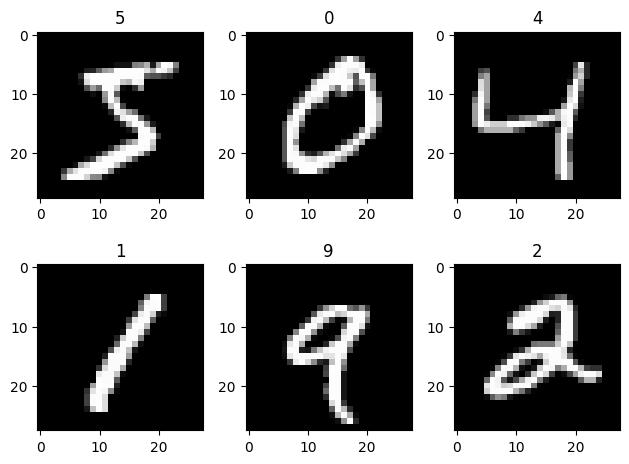

In [59]:
###################
# Your code goes here, what are the var names?
###################

for i in range(6):
  plt.subplot(2, 3, i + 1)
  im = train_data[i, ...].numpy()
  label = class_names[train_labels[i].item()]
  plt.imshow(im, cmap='gray', vmin=0.0, vmax=1.0)
  plt.title(label)
plt.tight_layout()
plt.show()


And we can also show the histogram of these images.


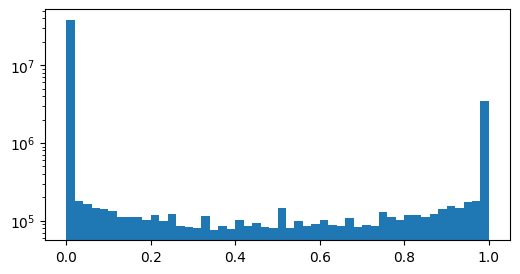

In [60]:
plt.figure(figsize=(6, 3))
result = plt.hist(train_data.flatten(), bins=50)
plt.yscale('log')
plt.show()


#### Question B.2. Finally, we need to get the mean and standard [1%]
deviation (std).

**Hint**: Torch has built-in functions to get the mean and standard
deviation. The mean should be around 0.13, and std should be around
0.31.


In [63]:
###################
# Your code goes here, what are the var names and methods?
###################

mean_train = torch.mean(train_data)
std_train = torch.std(train_data)
print(f'mean = {mean_train}, std = {std_train}')


mean = 0.13066047430038452, std = 0.30810782313346863


### Step 1.2. Define the data transformation (no questions)


In [64]:
# Define transformations for the training and test sets

transform_train = transforms.Compose([
    # Convert input to a float tensor. It automatically converts a
    # uint8 image to a float32 image.
    transforms.ToTensor(),
    # Normalize it to zero-mean, unit variance.
    transforms.Normalize((mean_train,), (std_train,))
])

# The transformation applied to the testing is the same as training
transform_test = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((mean_train,), (std_train,))
])


In [66]:
# Load the MNIST dataset
train_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=True,
    download=True,
    transform=transform_train
)

test_dataset = torchvision.datasets.MNIST(
    root='./data',
    train=False,
    download=True,
    transform=transform_test
)

# Create data loaders
batch_size = 64
train_loader = DataLoader(train_dataset, batch_size=batch_size,
                          shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size,
                         shuffle=False)


Let us visualize the loaded data again.

Note that:

* The image after loading is a floating-point image.
* The image is normalized, where the value is distributed around 0.


In each batch, the batch_image dimension is torch.Size([64, 1, 28, 28])
In each batch, the batch_label dimension is torch.Size([64])


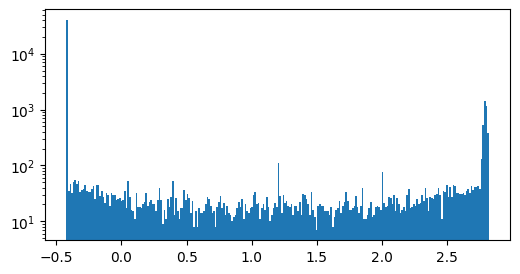

In [77]:
for batch_image, batch_label in train_loader:
  print(f'In each batch, the batch_image dimension is '
        f'{batch_image.shape}')
  print(f'In each batch, the batch_label dimension is '
        f'{batch_label.shape}')
  plt.figure(figsize=(6, 3))
  result = plt.hist(batch_image.flatten(), bins=256)
  plt.yscale('log')
  plt.show()
  break


## Step 2. Define other training options (no questions)


For the first training project, CPU is enough.

Still, if you like to (and have enough quota), you can always run it
with GPU.


In [68]:
# Check if CUDA is available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")


Using device: cpu


Also, we need to define the loss function.


In [69]:
loss_fn = nn.CrossEntropyLoss()


## Step 3. Define the network structure


### Question B.3 Network Structure [1%]


Let us create the first model, which is an MLP. Please use:

* 2 linear layers.
* The dimension of the intermediate layer is 128.
* The last layer should be a linear layer.
* Use ReLU as the activation function between the two linear layers.


In [82]:
class MLPNetwork(nn.Module):
  def __init__(self):
    super().__init__()
    # Flatten the 28x28 image into a 784-element vector
    self.flatten = nn.Flatten()
    # Define a MLP model here
    self.mlp = nn.Sequential(
      ###################
      # Your code goes here
      ###################
      nn.Linear(784, 128),
      nn.ReLU(),
      nn.Linear(128, 10)
    )

  def forward(self, x: torch.Tensor) -> torch.Tensor:
    # Pass the input through the layers
    x = self.flatten(x)
    logits = self.mlp(x)
    return logits

model = MLPNetwork().to(device)
print('==== This is the model we created ====')
print(model)


==== This is the model we created ====
MLPNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (mlp): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=10, bias=True)
  )
)


Calculate the number of trainable parameters.

For example, for a `nn.Linear(10, 20)`, the weight matrix has
10x20=200 parameters, and the bias has 20 parameters.

Hint: you can use `model.parameters()` to iterate all parameters.


In [86]:
def calc_model_params(model: nn.Module) -> int:
  #####################
  # Your code goes here
  # Please also add docstring
  #####################
  """
  Count the total number of parameters in a PyTorch model.

  Args:
      model (nn.Module): The PyTorch model.

  Returns:
      int: Total number of parameters in the model.
  """

  total_params = 0
  for param in model.parameters():
    total_params += param.numel()
  return total_params

print(f'There are {calc_model_params(model)} parameters in this '
      f'model')


There are 101770 parameters in this model


## Step 4: Training and Evaluation Loops (although no questions, but make it run correctly)


First, let us define a training loop that iterates over all the
batches of the training dataset.


In [83]:
def train_one_epoch(
    dataloader: torch.utils.data.DataLoader,
    model: nn.Module,
    loss_fn: nn.Module,
    optimizer: optim.Optimizer,
    loss_print_iter: int=100
  ) -> None:
  """
  Train the model for one epoch over all batches.

  Args:
    dataloader: DataLoader of the training set.
    model: The model to train.
    loss_fn: Loss function.
    optimizer: Optimizer used to update the model parameters.
    loss_print_iter: Print the loss every this many iterations.
  """
  num_train_samples = len(dataloader.dataset)

  # Set the model to the training mode
  model.train()

  for batch_index, (image, label) in enumerate(dataloader):
    image, label = image.to(device), label.to(device)

    # Compute prediction error
    pred = model(image)
    loss = loss_fn(pred, label)

    # Backpropagation

    # Computes gradients of the loss with respect to all parameters
    # in the model that require gradients, storing them in the .grad
    # attribute of each parameter.
    loss.backward()

    # Updates all the model parameters using the gradients computed
    # in the previous step, moving parameters in the direction that
    # reduces the loss.
    optimizer.step()

    # Clear gradient for next iterations.
    optimizer.zero_grad()

    if batch_index % loss_print_iter == 0:
      loss_v = loss.item()
      trained_samples = (batch_index + 1) * image.shape[0]
      print(f'loss: {loss_v:>7f} '
            f'[{trained_samples:>5d}/{num_train_samples:>5d}] ')

  return None


Also, define an evaluation loop that checks the model's performance
on the test dataset.


In [73]:
def test_all_samples(
    dataloader: torch.utils.data.DataLoader,
    model: nn.Module,
    loss_fn: nn.Module
) -> None:
  """
  Evaluate the model on all samples of a dataset.

  Args:
    dataloader: DataLoader of the test set.
    model: The model to evaluate.
    loss_fn: Loss function.
  """
  model.eval()  # Set the model to evaluation mode
  num_testing_samples = len(dataloader.dataset)
  num_batches = len(dataloader)
  test_loss, correct = 0, 0

  # Disable gradient calculation for inference
  with torch.no_grad():
    for image, label in dataloader:
      image, label = image.to(device), label.to(device)
      pred = model(image)
      test_loss += loss_fn(pred, label).item()
      correct += (pred.argmax(1) == label).type(
          torch.float).sum().item()

  test_loss /= num_batches
  correct /= num_testing_samples
  print(f'Test Error: \n Accuracy: {(100*correct):>0.1f}%, '
        f'Avg loss: {test_loss:>8f} \n')


At last, let us run the training. In each epoch:

* We loop over all training samples and update the network with
  `train_one_epoch`.
* We evaluate the network on the test set with `test_all_samples`.


In [84]:
torch.manual_seed(2026)
model = MLPNetwork().to(device)
epochs = 3   # Number of training epochs
optimizer = torch.optim.SGD(
  model.parameters(),    # All trainable parameters.
  lr=1e-3                # Learning rate
)

for t in range(epochs):
  print(f"Epoch {t+1}\n-------------------------------")
  # Run one training epoch
  train_one_epoch(train_loader, model, loss_fn, optimizer)
  # After each epoch, run testing on all samples
  test_all_samples(test_loader, model, loss_fn)

print("Training done!")


Epoch 1
-------------------------------
loss: 2.333756 [   64/60000] 
loss: 2.219168 [ 6464/60000] 
loss: 1.968154 [12864/60000] 
loss: 1.861457 [19264/60000] 
loss: 1.684592 [25664/60000] 
loss: 1.597991 [32064/60000] 
loss: 1.507526 [38464/60000] 
loss: 1.244843 [44864/60000] 
loss: 1.156286 [51264/60000] 
loss: 1.186995 [57664/60000] 
Test Error: 
 Accuracy: 80.0%, Avg loss: 1.044330 

Epoch 2
-------------------------------
loss: 1.130815 [   64/60000] 
loss: 0.983703 [ 6464/60000] 
loss: 0.910784 [12864/60000] 
loss: 0.872080 [19264/60000] 
loss: 0.918441 [25664/60000] 
loss: 0.858903 [32064/60000] 
loss: 0.589546 [38464/60000] 
loss: 0.802980 [44864/60000] 
loss: 0.845097 [51264/60000] 
loss: 0.717912 [57664/60000] 
Test Error: 
 Accuracy: 86.2%, Avg loss: 0.628461 

Epoch 3
-------------------------------
loss: 0.606476 [   64/60000] 
loss: 0.688586 [ 6464/60000] 
loss: 0.665505 [12864/60000] 
loss: 0.678210 [19264/60000] 
loss: 0.609987 [25664/60000] 
loss: 0.681867 [32064/6000

At last, let us test this model on real images.


torch.Size([64, 1, 28, 28])


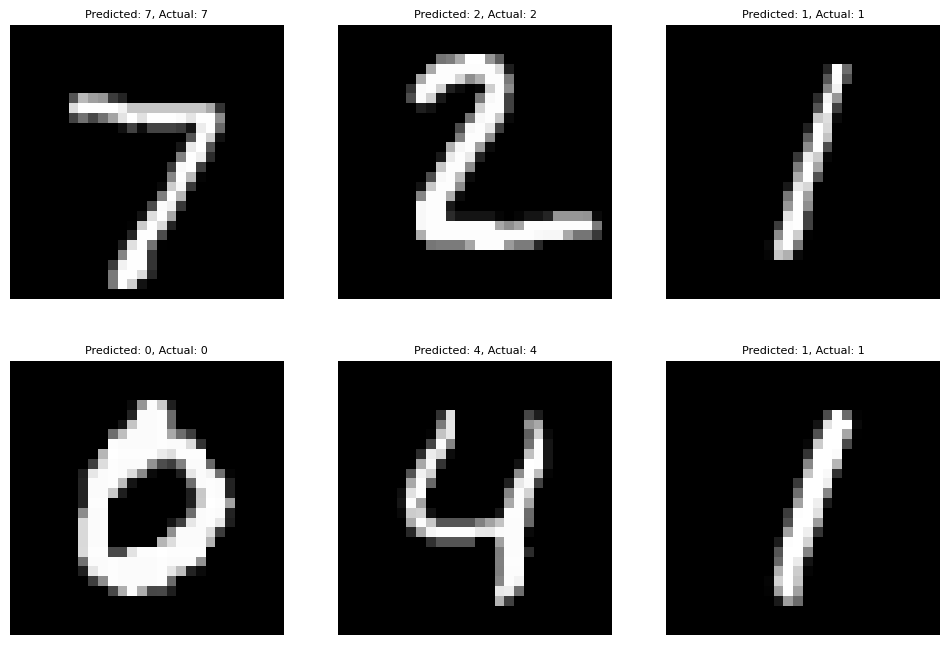

In [85]:
model.eval()
with torch.no_grad():
  for image, label in test_loader:
    print(image.shape)
    image = image.to(device)
    model_output = model(image[:6, ...])
    predicted_label = [class_names[x] for x in model_output.argmax(1)]
    actual_label = [class_names[x] for x in label[:6]]
    # Display the first images and their predictions
    plt.figure(figsize=(12, 8))
    for i in range(6):
      plt.subplot(2, 3, i + 1)
      plt.imshow(image[i, 0, ...], cmap='gray')
      plt.title(f'Predicted: {predicted_label[i]}, '
                f'Actual: {actual_label[i]}', fontsize=8)
      plt.axis('off')
    plt.show()
    break


## Question B.4. Visualize train / test loss curve [Optional 0%]


Write another version of the training pipeline, similar to step 4,
but record:

* The training loss and accuracy at each **iteration** (training one
  batch is one iteration): `train_acc` and `train_loss`.
* The exponential moving average (EMA) of them: `train_acc_ema` and
  `train_loss_ema`. This is very useful in visualization, as the
  original `train_acc` is very noisy (see the plot question below).
* The test accuracy and loss at each **epoch**: `test_acc` and
  `test_loss`.

Check this for details of EMA:

https://en.wikipedia.org/wiki/Exponential_smoothing

$$s_t = \beta \cdot s_{t-1} + (1 - \beta) \cdot x_t$$

where $\beta$ is a smoothing factor between 0 and 1 that you can
tune.

**Hints**:

* The easiest way is to copy the code of `train_one_epoch` and
  `test_all_samples` from Step 4 and modify them: record the batch
  accuracy and loss inside the training loop, and record the test
  accuracy and loss after each epoch.
* The accuracy of one batch can be computed as
  `(pred.argmax(1) == label).float().mean().item()`.
* When plotting `test_acc`, its x coordinates can be the iteration
  numbers at the end of each epoch, e.g.
  `(epoch + 1) * len(train_loader)`.


In [ ]:
#####################
# Your code goes here
#####################

train_acc = None
train_loss = None
train_acc_ema = None
train_loss_ema = None
test_acc = None
test_loss = None


In the next question, plot the following 3 curves in a single plot:

* `train_acc`
* `train_acc_ema`
* `test_acc`

Note that `train_acc` is very noisy. Tune the parameter of the EMA to
make `train_acc_ema` smooth.

The x-axis should be the iteration. Note that `test_acc` has much
fewer samples compared with `train_acc` (one value per epoch).

Hint: When plotting a curve, you can use `plt.plot(x, y)`.


In [ ]:
#####################
# Your code goes here
#####################


Similarly, plot the following 3 curves:

* `train_loss`
* `train_loss_ema`
* `test_loss`


In [ ]:
#####################
# Your code goes here
#####################


## Question B.5. Improve the model accuracy. [Optional 0%]


This model is definitely not the best. Can you try to make some
changes to improve the accuracy? You could try:

* Add more layers.
* Change the intermediate channel number.
* Change the number of epochs.
* Change the learning rate.
* ...

With some tuning, you should be able to achieve at least **95%** test
accuracy (with a more careful design, it can reach 97% or higher).

Still, if you cannot achieve 95%, you can instead record 2-3 models
you have tried (including the printed output of each training). If
you achieved 95%, just keep the model that achieves it.

You shall achieve a reasonable result with less than 7 min training
on CPU.


In [ ]:
class MLPNetwork2(nn.Module):
  #####################
  # Your code goes here
  #####################
  pass

model_v2 = MLPNetwork2()


And rerun your training and testing below.


In [ ]:
#####################
# Your code goes here
#####################


**Testing**

After training, run the test below. **Do not change it**. Modified
test blocks receive no mark for this question.


In [ ]:
test_all_samples(test_loader, model_v2, loss_fn)


## Question B.6. CNN. [Optional 0%]


Although we have not talked about CNN yet, you can try to train a
multi-layer CNN.

It is not easy to achieve much higher accuracy using CNN on MNIST
(compared to B.5), but you shall **reduce the number of parameters**:
your CNN should have fewer parameters than the MLP in B.3, while
keeping a comparable test accuracy.

Hint:

* You can try to use `nn.Conv2d` to create a convolution layer and
  `nn.MaxPool2d` to create a pooling layer.


In [ ]:
class ConvNetwork(nn.Module):
  #####################
  # Your code goes here
  #####################
  pass

model_v3 = ConvNetwork()


In [ ]:
print(f'There are {calc_model_params(model_v3)} parameters in this '
      f'model')


And rerun your training.


In [ ]:
#####################
# Your code goes here
#####################


**Testing**

After training, run the test below. **Do not change it**. Modified
test blocks receive no mark for this question.


In [ ]:
test_all_samples(test_loader, model_v3, loss_fn)
